# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

Джерело: Kaggle, hellbuoy/car-price-prediction. Локальна копія CSV отримана з відкритого дзеркала [DATASETS](https://github.com/ameenmanna8824/DATASETS/blob/main/CarPrice_Assignment.csv).


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown
file=Path('CarPrice_Assignment.csv')
if not file.exists():file=Path('Джерельні файли')/file
if not file.exists():file='https://raw.githubusercontent.com/ameenmanna8824/DATASETS/main/CarPrice_Assignment.csv'
df=pd.read_csv(file)
print('Розмір:',df.shape)
print('Ціль: price')
display(df.head())
df.info()
display(df.describe())

Розмір: (205, 26)
Ціль: price


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
display(df.isna().sum())
print('Повні дублікати:',df.duplicated().sum())
print('Дублікати без car_ID:',df.drop(columns='car_ID').duplicated().sum())
display(df.nunique())

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати: 0
Дублікати без car_ID: 0


car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64

Перевірено пропуски, повні дублікати й дублікати без ідентифікатора. Різні ціни за схожих характеристик не є повними дублікатами.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids=df['car_ID'].copy()
features=df.drop(columns=['car_ID','price'])
y=df['price']
print('car_ID вилучено з предикторів:', 'car_ID' not in features)

car_ID вилучено з предикторів: True


Ідентифікатор залишено лише для таблиці результатів.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


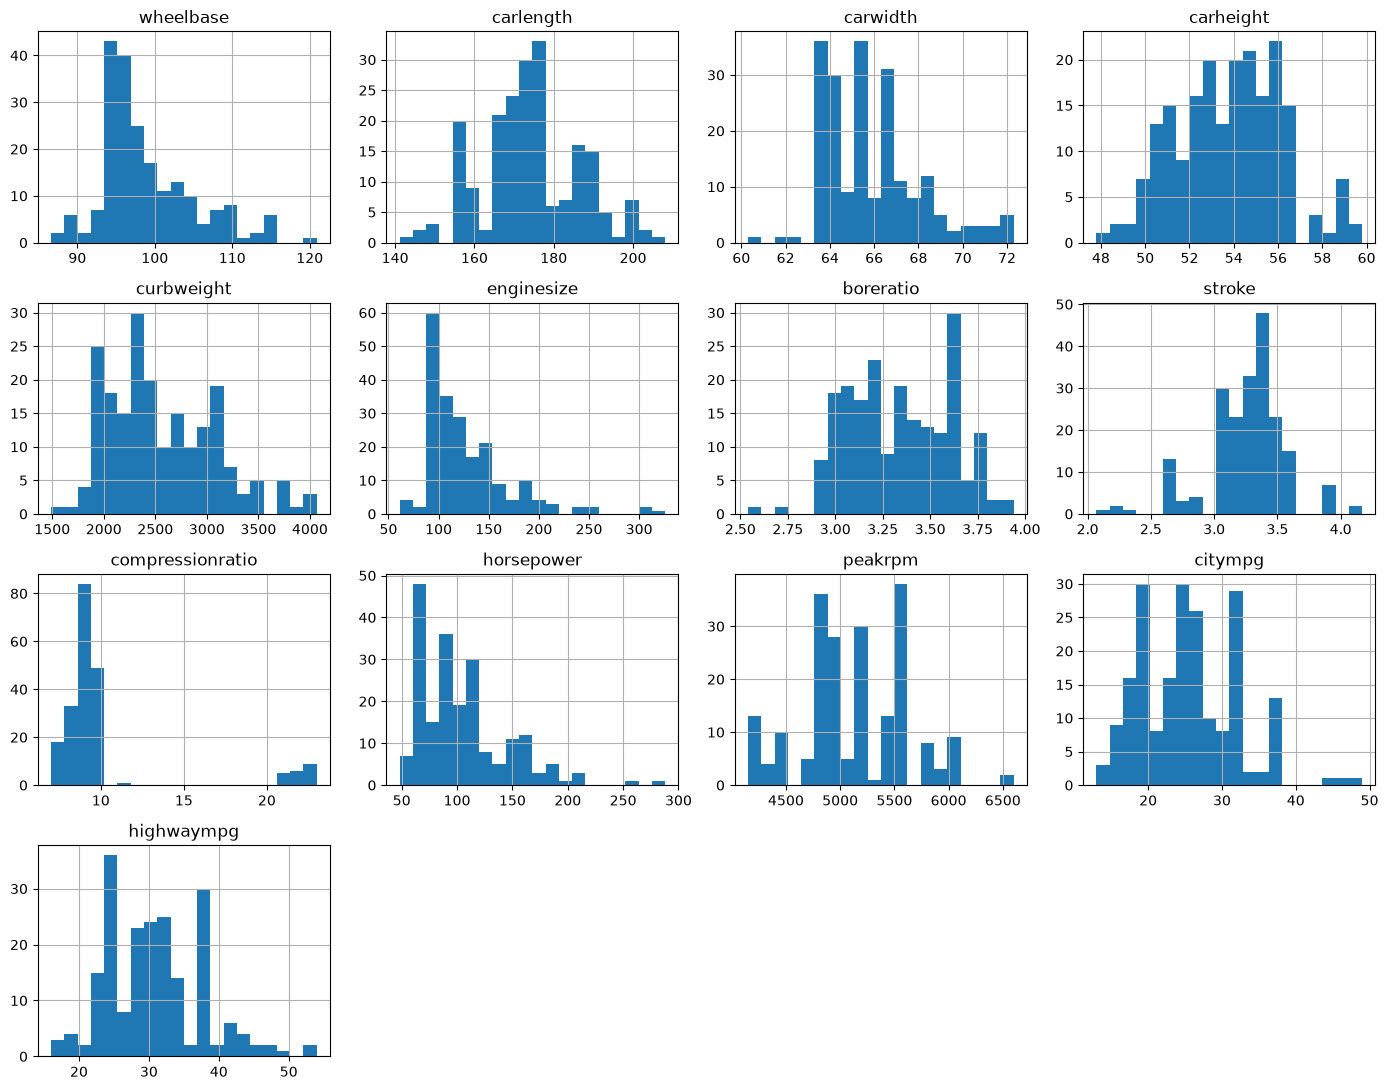

compressionratio    2.610862
enginesize          1.947655
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
stroke             -0.689705
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
dtype: float64

Найбільша абсолютна асиметрія: compressionratio, enginesize, horsepower


In [4]:
continuous=features.select_dtypes('number').columns.drop('symboling').tolist()
features[continuous].hist(figsize=(14,11),bins=20)
plt.tight_layout()
plt.show()
skew_all=features[continuous].skew().sort_values(key=abs,ascending=False)
display(skew_all)
print('Найбільша абсолютна асиметрія:', ', '.join(skew_all.index[:3]))

Розподіли неоднорідні; найбільш асиметричні ознаки наведено у виводі. Цей огляд описовий; параметри обробки далі визначаються лише на train.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку : 80%;
- тестову вибірку : 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(features,y,test_size=0.2,random_state=42)
ids_train=car_ids.loc[X_train.index]
ids_test=car_ids.loc[X_test.index]
print('Train:',len(X_train),'Test:',len(X_test))

Train:

 164 Test: 41


Відкладено 20% спостережень. Індекси збережено для зіставлення з car_ID.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
from sklearn.base import BaseEstimator,TransformerMixin,clone
class IQRClipper(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None):
        self.columns_=[c for c in X.select_dtypes('number').columns if c!='symboling']
        q1=X[self.columns_].quantile(0.25)
        q3=X[self.columns_].quantile(0.75)
        self.lower_=q1-1.5*(q3-q1)
        self.upper_=q3+1.5*(q3-q1)
        return self
    def transform(self,X):
        out=X.copy()
        out[self.columns_]=out[self.columns_].clip(self.lower_,self.upper_,axis=1)
        return out
clipper=IQRClipper().fit(X_train)
outlier_counts=((X_train[continuous]<clipper.lower_)|(X_train[continuous]>clipper.upper_)).sum()
display(outlier_counts.sort_values(ascending=False))
clipped_train=clipper.transform(X_train)
clipped_test=clipper.transform(X_test)
print('Крайні значення обмежено за train. Рядки та цільову ціну не видалено.')

compressionratio    20
stroke              16
carwidth            10
horsepower           7
enginesize           7
wheelbase            6
peakrpm              2
highwaympg           1
boreratio            1
curbweight           0
carheight            0
carlength            0
citympg              0
dtype: int64

Крайні значення обмежено за train. Рядки та цільову ціну не видалено.


Обмеження IQR зберігає всі автомобілі невеликої вибірки. Межі не залежать від test або price.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


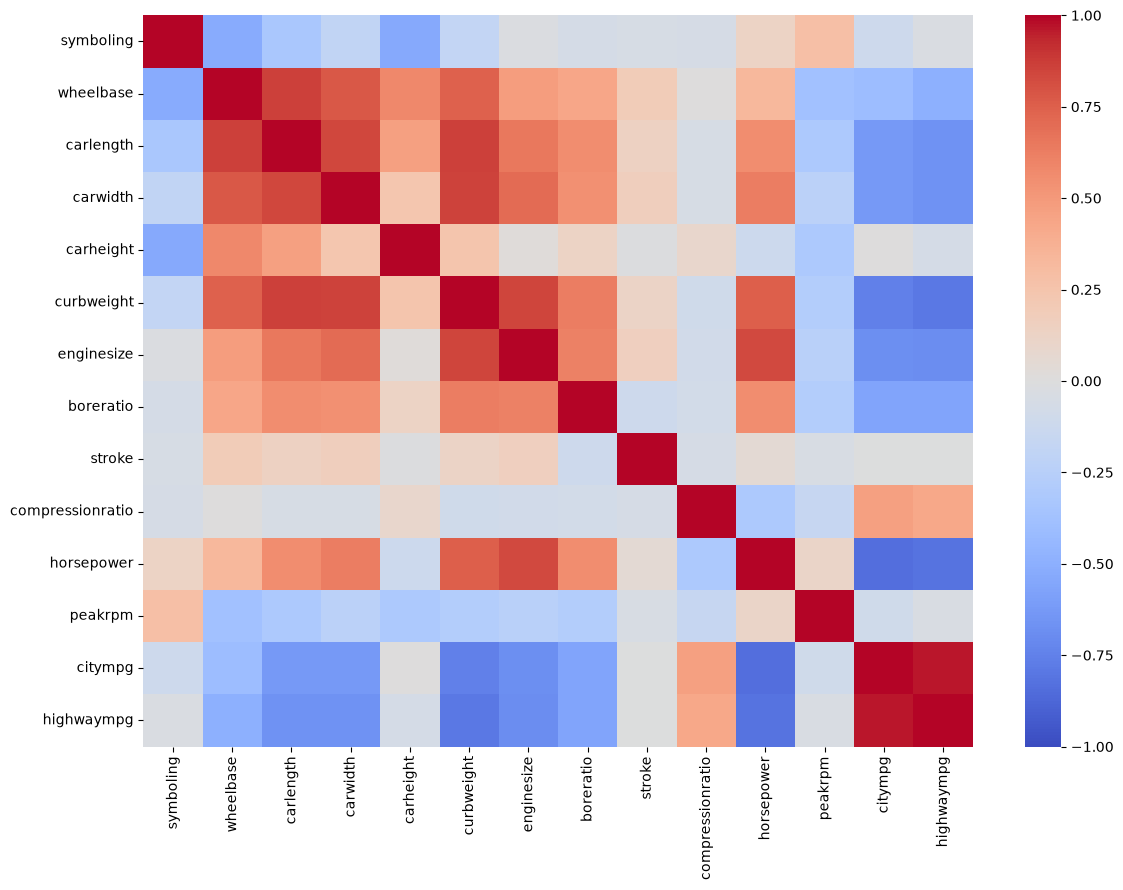

,Ознака 1,Ознака 2,r
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047
3,citympg,highwaympg,0.963620


Вилучено: ['carwidth', 'citympg', 'carlength']
Першими збережено ознаки з сильнішим зв’язком із ціною на train.


In [7]:
class CorrelationSelector(BaseEstimator,TransformerMixin):
    def __init__(self,threshold=0.85):self.threshold=threshold
    def fit(self,X,y):
        numeric=X.select_dtypes('number')
        corr=numeric.corr().abs()
        ranking=numeric.corrwith(pd.Series(y,index=X.index)).abs().sort_values(ascending=False).index
        kept=[]
        self.dropped_=[]
        for col in ranking:
            if any(corr.loc[col,k]>self.threshold for k in kept):self.dropped_.append(col)
            else:kept.append(col)
        return self
    def transform(self,X):return X.drop(columns=self.dropped_)
corr=clipped_train.select_dtypes('number').corr()
plt.figure(figsize=(12,9))
sns.heatmap(corr,cmap='coolwarm',vmin=-1,vmax=1)
plt.tight_layout()
plt.show()
pairs=[]
for i,a in enumerate(corr.columns):
    for b in corr.columns[i+1:]:
        if abs(corr.loc[a,b])>0.85:pairs.append({'Ознака 1':a,'Ознака 2':b,'r':corr.loc[a,b]})
display(pd.DataFrame(pairs))
selector=CorrelationSelector().fit(clipped_train,y_train)
selected_train=selector.transform(clipped_train)
selected_test=selector.transform(clipped_test)
print('Вилучено:',selector.dropped_)
print('Першими збережено ознаки з сильнішим зв’язком із ціною на train.')

Кореляційний відбір залишає один предиктор із кожної сильно пов’язаної групи, надаючи перевагу сильнішому зв’язку з price на train.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo-Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo-Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
from sklearn.compose import ColumnTransformer,make_column_selector
from sklearn.preprocessing import PowerTransformer,StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
def continuous_columns(X):return [c for c in X.select_dtypes('number').columns if c!='symboling']
def discrete_columns(X):return [c for c in ['symboling'] if c in X.columns]
preprocessing=ColumnTransformer([
    ('continuous',Pipeline([('impute',SimpleImputer(strategy='median')),('yeojohnson',PowerTransformer(method='yeo-johnson',standardize=False)),('scale',StandardScaler())]),continuous_columns),
    ('discrete',StandardScaler(),discrete_columns),
    ('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),make_column_selector(dtype_include=object))
])
prep_check=clone(preprocessing).fit(selected_train)
print('Після перетворення:',prep_check.transform(selected_train).shape,prep_check.transform(selected_test).shape)

Після перетворення: (164, 172) (41, 172)


Один механізм передобробки застосовується до всіх моделей. Невідомі категорії test не спричиняють помилку.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
cols=continuous_columns(selected_train)
transformed=prep_check.named_transformers_['continuous'].transform(selected_train[cols])
skew_comparison=pd.DataFrame({'До':selected_train[cols].skew(),'Після':pd.DataFrame(transformed,columns=cols).skew()})
display(skew_comparison)
print('Середня абсолютна асиметрія:',skew_comparison.abs().mean().to_dict())

,До,Після
wheelbase,0.935764,0.020429
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Середня абсолютна асиметрія: {'До': 0.4289286810153238, 'Після': 0.02290436316862212}


Ефективність Yeo-Johnson оцінено за зміною абсолютної асиметрії; зменшення не гарантується для кожного стовпця.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,mean_absolute_percentage_error
regressors={'Linear Regression':LinearRegression(),'Ridge':Ridge(alpha=10),'Lasso':Lasso(alpha=10,max_iter=30000),'Random Forest':RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=2),'Gradient Boosting':GradientBoostingRegressor(random_state=42),'SVR':SVR(C=10000,epsilon=100)}
models={name:Pipeline([('clip',IQRClipper()),('select',CorrelationSelector()),('prep',clone(preprocessing)),('model',model)]) for name,model in regressors.items()}
print(list(models))

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting', 'SVR']


У кожній моделі IQR, відбір і перетворення навчаються в Pipeline тільки на train.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² : чим більше, тим краще;
- MAE, MSE, MAPE : чим менше, тим краще.


In [11]:
rows=[]
predictions={}
for name,model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    predictions[name]=pred
    rows.append({'Модель':name,'Train R²':r2_score(y_train,model.predict(X_train)),'R²':r2_score(y_test,pred),'MAE':mean_absolute_error(y_test,pred),'MSE':mean_squared_error(y_test,pred),'MAPE, %':100*mean_absolute_percentage_error(y_test,pred)})
results=pd.DataFrame(rows).set_index('Модель').sort_values('R²',ascending=False)
display(results)

,Train R²,R²,MAE,MSE,"MAPE, %"
Модель,,,,,
Random Forest,0.985629,0.953781,1367.500561,3.648690e+06,9.949217
Gradient Boosting,0.991501,0.933568,1660.090127,5.244394e+06,12.365861
SVR,0.966630,0.858770,2153.554623,1.114923e+07,16.928933
Lasso,0.970823,0.775206,2608.845842,1.774613e+07,19.380184
Ridge,0.864327,0.731252,3195.846692,2.121601e+07,27.984356
Linear Regression,0.992994,0.529797,4184.431944,3.711970e+07,30.633588


Великий розрив між Train R² і Test R² вказує на можливе перенавчання. Тест містить лише 41 автомобіль, тому оцінки залежать від поділу.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування `price` є задачею регресії, оскільки ціна є неперервною числовою величиною. Logistic Regression оцінює ймовірності дискретних класів, тому безпосередньо передбачати ціну не може. Для цієї задачі використано регресійні моделі, які повертають числовий прогноз.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


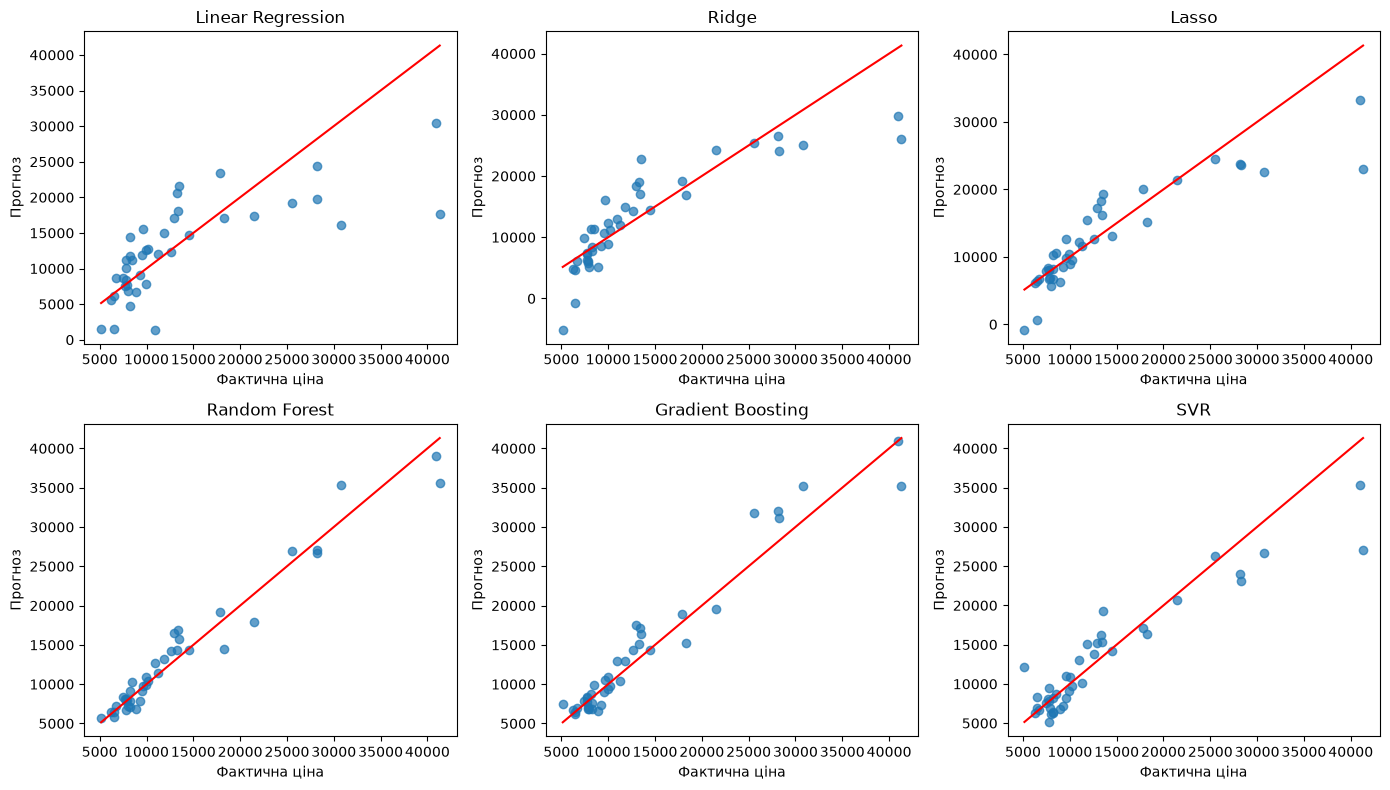

In [12]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    ax.scatter(y_test,pred,alpha=0.7)
    ax.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],color='red')
    ax.set(title=name,xlabel='Фактична ціна',ylabel='Прогноз')
plt.tight_layout()
plt.show()

Чим ближче точки до червоної діагоналі, тим менша помилка. Окремі великі відхилення впливають на MSE сильніше.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
sample=X_test.sample(10,random_state=42)
table=pd.DataFrame({'car_ID':ids_test.loc[sample.index],'Фактична ціна':y_test.loc[sample.index],'Прогнозована ціна':models['Random Forest'].predict(sample)})
table['Абсолютна помилка']=(table['Фактична ціна']-table['Прогнозована ціна']).abs()
table['Абсолютна помилка, %']=100*table['Абсолютна помилка']/table['Фактична ціна']
display(table)
print('Середня відсоткова помилка цих 10 прогнозів:',table['Абсолютна помилка, %'].mean())

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна помилка, %"
25,26,6692.0,7242.4550,550.4550,8.225568
175,176,9988.0,10928.8450,940.8450,9.419754
147,148,10198.0,10466.2100,268.2100,2.630025
16,17,41315.0,35549.7525,5765.2475,13.954369
68,69,28248.0,26720.3325,1527.6675,5.408055
146,147,7463.0,8405.9150,942.9150,12.634530
143,144,9960.0,9898.0800,61.9200,0.621687
84,85,14489.0,14408.7300,80.2700,0.554006
194,195,12940.0,16551.8750,3611.8750,27.912481
159,160,7788.0,7826.6150,38.6150,0.495827


Середня відсоткова помилка цих 10 прогнозів: 8.185630253033896


Ця таблиця є прикладом для 10 випадкових test-об’єктів; основні метрики обчислено за всією тестовою вибіркою.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Підсумковий висновок наведено після виконання всіх розрахунків.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.


## Підсумковий висновок
Порівняно шість регресійних моделей за однакової підготовки даних. Найвищий тестовий R² отримала **Random Forest**: 0.9538. Її MAE дорівнює 1367.50, MSE дорівнює 3648689.69, MAPE становить 9.95%. Метрики всіх моделей наведено в порівняльній таблиці, а розрив Train/Test R² дає змогу оцінити ризик перенавчання. Ціну не використано для обрізання викидів, car_ID не використано для навчання. Межі IQR, відбір за кореляцією та перетворення оцінено лише на train. Обробка зменшує вплив крайніх значень і забезпечує спільний формат ознак, але її окремий внесок у точність без контрольного експерименту не визначався. Для дорожчих автомобілів можливі значні абсолютні помилки, тому результат невеликої тестової вибірки не слід узагальнювати на весь ринок.